## 1. Імпорт бібліотек і персональні параметри

`SEED = 1000 × VARIANT + STUDENT_ID`

In [2]:
import os, re, time, hashlib, unicodedata, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import pytesseract
from PIL import Image, ImageDraw, ImageFont
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

STUDENT = "Курилів В. І."
VARIANT = 7
STUDENT_ID = 574
SEED = 1000 * VARIANT + STUDENT_ID
rng = np.random.default_rng(SEED)

FONTS = [
    "/System/Library/Fonts/Supplemental/Arial.ttf",
    "/System/Library/Fonts/Supplemental/Times New Roman.ttf",
    "/System/Library/Fonts/Supplemental/Georgia.ttf",
    "/System/Library/Fonts/Supplemental/Verdana.ttf",
]
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def stamp(ax, title):
    """Заголовок графіка з персональним підписом студента."""
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

print("SEED =", SEED)
print("Tesseract", pytesseract.get_tesseract_version(), "| мови:",
      [l for l in pytesseract.get_languages() if l in ("ukr", "eng")])
print("Шрифти є:", all(os.path.exists(f) for f in FONTS))

SEED = 7574
Tesseract 5.5.3 | мови: ['eng', 'ukr']
Шрифти є: True


## 2. Формування синтетичного набору з еталонною розміткою

Джерело тексту: Г. Квітка-Основ'яненко, «Маруся», https://www.ukrlib.com.ua/books/printit.php?tid=1018

Підготовка `corpus.txt`:
- у тексті на сайті замість кириличної «і» стоїть латинська «i», тому латинські `i`/`I` замінено на кириличні `і`/`І`
- текст розбито на речення, залишено речення довжиною 20–70 символів

Вибираємо 40 речень і відтворюємо кожне на 7 рівнях гаусового розмиття

In [3]:
with open("corpus.txt", encoding="utf-8") as f:
    corpus = [s.strip() for s in f if 20 <= len(s.strip()) <= 70]
lines = [str(s) for s in rng.choice(corpus, size=40, replace=False)]
print("Речень у corpus.txt:", len(corpus), "| вибрано:", len(lines))

Речень у corpus.txt: 759 | вибрано: 40


In [4]:
def render_line(text, font_path, size=32, pad=12):
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)

def degrade(img, kind, level, rng):
    out = img.astype(np.float32)
    if kind == "blur" and level > 0:
        out = cv2.GaussianBlur(out, (0, 0), level)
    return np.clip(out, 0, 255).astype(np.uint8)

In [5]:
FACTOR, LEVELS = "blur", [0, 0.5, 1, 1.5, 2, 2.5, 3]
records = []
for i, text in enumerate(lines):
    font = FONTS[i % len(FONTS)]
    clean = render_line(text, font, size=int(rng.integers(22, 36)))
    for lvl in LEVELS:
        path = f"data/{i:03d}_{FACTOR}_{lvl}.png"
        cv2.imwrite(path, degrade(clean, FACTOR, lvl, rng))
        records.append({"id": i, "level": lvl, "path": path, "gt": text,
                        "font": os.path.basename(font)})
ds = pd.DataFrame(records)
ds.to_csv("data/ground_truth.csv", index=False)
with open("data/ground_truth.csv", "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()[:16]
print("Записів:", len(ds), "| SHA-256 еталону:", sha)

Записів: 280 | SHA-256 еталону: 120b7a735fea41c0


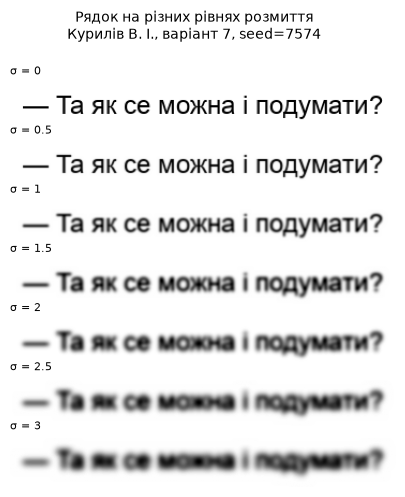

In [6]:
fig, axes = plt.subplots(len(LEVELS), 1, figsize=(7, 0.75 * len(LEVELS)))
for ax, lvl in zip(axes, LEVELS):
    img = cv2.imread(f"data/000_{FACTOR}_{lvl}.png", cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"σ = {lvl}", fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"Рядок на різних рівнях розмиття\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10, y=1.02)
fig.savefig("figures/fig0_samples.png", dpi=150, bbox_inches="tight")

## 3. Відкритий набір даних IAM

IAM Handwriting, рядки англійського рукопису (`Teklia/IAM-line`, частина `test`). Вибираємо 100 рядків за SEED, зберігаємо зображення та індекси зразків для відтворюваності

In [7]:
from datasets import load_dataset

hf = load_dataset("Teklia/IAM-line", split="test")
print(hf)

os.makedirs("open_data", exist_ok=True)
iam_idx = sorted(int(k) for k in rng.choice(len(hf), size=100, replace=False))
iam = []
for k in iam_idx:
    sample = hf[k]
    path = f"open_data/iam_{k:04d}.png"
    sample["image"].save(path)
    iam.append({"idx": k, "path": path, "gt": sample["text"]})
iam = pd.DataFrame(iam)
iam.to_csv("open_data/iam_ids.csv", index=False)
print("Зразків IAM:", len(iam))
iam.head()

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Dataset({
    features: ['image', 'text'],
    num_rows: 2915
})
Зразків IAM: 100


,idx,path,gt
0,40,open_data/iam_0040.png,"Dennis Brogan , Shelagh Delaney , and Alan Sil..."
1,78,open_data/iam_0078.png,text of the Gospel .
2,85,open_data/iam_0085.png,which is most likely to have been the original
3,95,open_data/iam_0095.png,it is now used to mark a paragraph ending . Fr...
4,138,open_data/iam_0138.png,A natural transition from gardens and


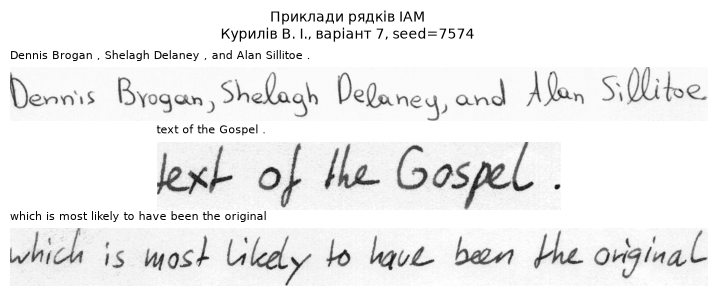

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(9, 3))
for ax, r in zip(axes, iam.head(3).itertuples()):
    ax.imshow(Image.open(r.path), cmap="gray")
    ax.set_title(r.gt, fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"Приклади рядків IAM\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10, y=1.05)
fig.savefig("figures/fig0_iam_samples.png", dpi=150, bbox_inches="tight")

## 4. Гіпотези до експерименту

Записано до запуску розпізнавання

1. **H1 (синтетика, розмиття).** На чистих синтетичних рядках (σ = 0) Tesseract матиме CER не більше 2 %, бо це друкований текст, на якому він навчений. CER Tesseract вперше перевищить 10 % при σ ≈ 2, бо розмиття зливає тонкі штрихи сусідніх літер.
2. **H2 (друкований інструмент проти рукописного, IAM).** На рукописному наборі IAM TrOCR матиме CER не більше 10 %, а Tesseract не менше 40 %, бо Tesseract навчений на друкованому тексті і не розпізнає злиті рукописні літери.
3. **H3 (попередня обробка).** Бінаризація Оцу погіршить CER TrOCR щонайменше на 2 відсоткові пункти, бо нейромережа навчена на зображеннях у відтінках сірого, а бінаризація втрачає деталі штрихів
4. **H4 (власні фото).** CER на власних фотографіях буде у 3–5 разів вищим, ніж на IAM, для обох інструментів, бо фото мають фон, нерівне освітлення і нахил, а IAM є чистими сканами.

## 5. Попередня обробка

In [9]:
def preprocess(img, steps=()):
    out = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if "upscale" in steps:
        out = cv2.resize(out, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    if "sharpen" in steps:
        blur = cv2.GaussianBlur(out, (0, 0), 2)
        out = cv2.addWeighted(out, 1.5, blur, -0.5, 0)
    if "binarize" in steps:
        out = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    if "adaptive" in steps:
        out = cv2.adaptiveThreshold(out, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY, 31, 15)
    return out

## 6. Розпізнавання двома інструментами

- **Tesseract 5**: `lang="ukr+eng"` для українських даних, `lang="eng"` для англійських.
- **TrOCR**: `microsoft/trocr-base-handwritten` для англійського рукопису, `Hukyl/trocr-large-uk-handwritten` для українського.

In [10]:
def ocr_tesseract(img, lang="ukr+eng", psm=7):
    t0 = time.perf_counter()
    d = pytesseract.image_to_data(img, lang=lang, config=f"--oem 1 --psm {psm}",
                                  output_type=pytesseract.Output.DICT)
    words = [(w, float(c)) for w, c in zip(d["text"], d["conf"]) if w.strip() and float(c) >= 0]
    text = " ".join(w for w, _ in words)
    conf = np.mean([c for _, c in words]) / 100 if words else 0.0
    return text, conf, time.perf_counter() - t0

In [11]:
import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel, logging
logging.set_verbosity_error()

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
TROCR = {}
for lang, name in {"en": "microsoft/trocr-base-handwritten",
                   "uk": "Hukyl/trocr-large-uk-handwritten"}.items():
    TROCR[lang] = (TrOCRProcessor.from_pretrained(name),
                   VisionEncoderDecoderModel.from_pretrained(name).to(DEVICE).eval())

def ocr_trocr(img, lang="uk"):
    proc, model = TROCR[lang]
    t0 = time.perf_counter()
    rgb = Image.fromarray(img).convert("RGB")
    px = proc(images=rgb, return_tensors="pt").pixel_values.to(DEVICE)
    with torch.no_grad():
        out = model.generate(px, max_new_tokens=128, num_beams=1, output_scores=True, return_dict_in_generate=True)
    scores = model.compute_transition_scores(out.sequences, out.scores, normalize_logits=True)
    text = proc.batch_decode(out.sequences, skip_special_tokens=True)[0]
    conf = float(scores[0].exp().mean())   # середня ймовірність токенів
    return text, conf, time.perf_counter() - t0

Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/636 [00:00<?, ?it/s]

## 7. Розпізнавання синтетичного набору

Кожне з 280 зображень розпізнається двома інструментами без обробки (`raw`) і з обробкою (`prep`: збільшення, підвищення різкості, бінаризація Оцу). Для кожного запуску зберігаються текст, впевненість і час.

In [12]:
ENGINES = {"Tesseract": lambda im: ocr_tesseract(im, "ukr+eng"),
           "TrOCR": lambda im: ocr_trocr(im, "uk")}
PREP = {"raw": (), "prep": ("upscale", "sharpen", "binarize")}

rows = []
for r in ds.itertuples():
    img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    for eng, fn in ENGINES.items():
        for prep_name, steps in PREP.items():
            text, conf, sec = fn(preprocess(img, steps))
            rows.append({"id": r.id, "level": r.level, "engine": eng, "prep": prep_name,
                         "gt": r.gt, "pred": text, "conf": conf, "sec": sec})
res = pd.DataFrame(rows)
print("Запусків розпізнавання:", len(res))

Запусків розпізнавання: 1120


## 8. Обчислення метрик

In [13]:
APOSTROPHES = "\u2019\u02bc\u2018\u0060\u00b4"
DASHES = "\u2014\u2013"
QUOTES = "\u00ab\u00bb\u201c\u201d\u201e"

def normalize(s):
    s = unicodedata.normalize("NFC", str(s))
    for a in APOSTROPHES:
        s = s.replace(a, "'")
    s = s.replace("--", "-")
    for d in DASHES:
        s = s.replace(d, "-")
    for q in QUOTES:
        s = s.replace(q, '"')
    s = re.sub(r"\s+([,.;:!?)])", r"\1", s)
    return re.sub(r"\s+", " ", s).strip()

def cer(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    return Levenshtein.distance(gt, pred) / max(1, len(gt))

def wer(gt, pred):
    gt, pred = normalize(gt).split(), normalize(pred).split()
    return Levenshtein.distance(gt, pred) / max(1, len(gt))

res["cer"] = [cer(g, p) for g, p in zip(res["gt"], res["pred"])]
res["wer"] = [wer(g, p) for g, p in zip(res["gt"], res["pred"])]
res.to_csv("results.csv", index=False)

summary = (res.groupby(["engine", "prep", "level"])
              .agg(CER_mean=("cer", "mean"), CER_median=("cer", "median"),
                   WER_mean=("wer", "mean"), sec_mean=("sec", "mean"))
              .round(3))
summary

CER_mean  CER_median  WER_mean  sec_mean
engine    prep level                                          
Tesseract prep 0.0       0.010       0.000     0.032     0.102
               0.5       0.011       0.000     0.040     0.102
               1.0       0.005       0.000     0.021     0.104
               1.5       0.013       0.000     0.037     0.103
               2.0       0.084       0.037     0.232     0.111
               2.5       0.307       0.237     0.538     0.114
               3.0       0.498       0.446     0.806     0.118
          raw  0.0       0.006       0.000     0.023     0.100
               0.5       0.008       0.000     0.030     0.101
               1.0       0.004       0.000     0.020     0.102
               1.5       0.032       0.000     0.049     0.099
               2.0       0.082       0.021     0.160     0.105
               2.5       0.152       0.053     0.356     0.111
               3.0       0.389       0.365     0.691     0.120
TrOCR     prep 0.0       0.059       0.033     0.210     2.486
               0.5       0.055       0.031     0.214     2.529
               1.0       0.058       0.033     0.225     2.516
               1.5       0.112       0.057     0.330     2.535
               2.0       0.282       0.257     0.575     2.531
               2.5       0.492       0.500     0.817     2.558
               3.0       0.641       0.659     0.907     2.403
          raw  0.0       0.054       0.041     0.235     2.417
               0.5       0.058       0.041     0.220     2.444
               1.0       0.101       0.075     0.325     2.381
               1.5       0.146       0.106     0.420     2.322
               2.0       0.227       0.176     0.567     2.262
               2.5       0.387       0.404     0.728     2.092
               3.0       0.630       0.691     0.900     1.676

In [14]:
(res.pivot_table(index=["engine", "prep"], columns="level", values="cer") * 100).round(1)

level           0.0  0.5   1.0   1.5   2.0   2.5   3.0
engine    prep                                        
Tesseract prep  1.0  1.1   0.5   1.3   8.4  30.7  49.8
          raw   0.6  0.8   0.4   3.2   8.2  15.2  38.9
TrOCR     prep  5.9  5.5   5.8  11.2  28.2  49.2  64.1
          raw   5.4  5.8  10.1  14.6  22.7  38.7  63.0

## 9. Розпізнавання відкритого набору IAM

100 рядків англійського рукопису, обидва інструменти англійською мовою, без обробки і з обробкою

In [15]:
ENGINES_EN = {"Tesseract": lambda im: ocr_tesseract(im, "eng"),
              "TrOCR": lambda im: ocr_trocr(im, "en")}
rows = []
for r in iam.itertuples():
    img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    for eng, fn in ENGINES_EN.items():
        for prep_name, steps in PREP.items():
            text, conf, sec = fn(preprocess(img, steps))
            rows.append({"idx": r.idx, "engine": eng, "prep": prep_name,
                         "gt": r.gt, "pred": text, "conf": conf, "sec": sec})
res_iam = pd.DataFrame(rows)
res_iam["cer"] = [cer(g, p) for g, p in zip(res_iam["gt"], res_iam["pred"])]
res_iam["wer"] = [wer(g, p) for g, p in zip(res_iam["gt"], res_iam["pred"])]
res_iam.to_csv("results_iam.csv", index=False)
res_iam.groupby(["engine", "prep"])[["cer", "wer", "sec"]].mean().round(3)

cer    wer    sec
engine    prep                     
Tesseract prep  0.605  0.957  0.129
          raw   0.608  0.981  0.124
TrOCR     prep  0.052  0.152  0.657
          raw   0.050  0.145  0.647

## 10. Обробка власних фотографій

Конвеєр для фотографії сторінки:
1. зменшення до 2000 пікселів по довшій стороні;
2. пошук аркуша і корекція перспективи за чотирма кутами. Аркуш виділяється за низькою насиченістю кольору;
3. вирівнювання нахилу;
4. Tesseract розпізнає всю сторінку (`--psm 6`);
5. TrOCR розпізнає лише окремі рядки, тому сторінка ділиться на рядки за горизонтальним профілем чорнила;

Варіанти обробки: без обробки (`raw`) і адаптивна бінаризація (`adaptive`)

In [16]:
import glob, json
from PIL import ExifTags
from scipy.signal import find_peaks

def exif_info(path):
    exif = Image.open(path).getexif()
    tags = {ExifTags.TAGS.get(k, k): v for k, v in exif.items()}
    return tags.get("DateTime"), tags.get("Model")

def order_corners(pts):
    pts = pts.reshape(4, 2).astype(np.float32)
    s, dif = pts.sum(1), np.diff(pts, axis=1).ravel()
    return np.float32([pts[s.argmin()], pts[dif.argmin()],
                       pts[s.argmax()], pts[dif.argmax()]])

def find_page(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    mask = ((hsv[..., 1] < 40) & (hsv[..., 2] > 90)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((15, 15), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((25, 25), np.uint8))
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hull = cv2.convexHull(max(cnts, key=cv2.contourArea))
    for eps in np.arange(0.02, 0.1, 0.01):
        approx = cv2.approxPolyDP(hull, eps * cv2.arcLength(hull, True), True)
        if len(approx) == 4:
            return order_corners(approx)
    return None

def warp_page(img, corners, width=1100):
    tl, tr, br, bl = corners
    h = int(width * max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
            / max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl)))
    dst = np.float32([[0, 0], [width, 0], [width, h], [0, h]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(corners, dst), (width, h))

def ink_mask(page):
    ink = cv2.adaptiveThreshold(page, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY_INV, 31, 15)
    m = int(0.04 * min(ink.shape))
    ink[:, :m] = 0; ink[:, -m:] = 0; ink[:m] = 0; ink[-m:] = 0
    return ink

def rotate(img, angle, border):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderValue=border)

def deskew(page):
    ink = ink_mask(page)
    angle = max(np.arange(-6, 6.01, 0.25), key=lambda a: np.var(rotate(ink, a, 0).sum(1)))
    return rotate(page, angle, 255)

def split_lines(page):
    ink = ink_mask(page)
    prof = np.convolve(ink.sum(1) / 255, np.ones(15) / 15, mode="same")
    peaks, _ = find_peaks(prof, distance=30, prominence=0.12 * prof.max())
    cuts = ([max(0, peaks[0] - 60)]
            + [int(np.argmin(prof[a:b]) + a) for a, b in zip(peaks[:-1], peaks[1:])]
            + [min(len(prof), peaks[-1] + 60)])
    lines = []
    for a, b in zip(cuts[:-1], cuts[1:]):
        cols = np.convolve(ink[a:b].sum(0) > 0, np.ones(41), mode="same") > 0
        if np.median(page[a:b]) > 110 and cols.mean() > 0.3:
            lines.append((a, b))
    return lines

In [17]:
def ocr_trocr_page(page, lang):
    texts, confs, total = [], [], 0.0
    for a, b in split_lines(page):
        text, conf, sec = ocr_trocr(page[a:b], lang)
        texts.append(text); confs.append(conf); total += sec
    return "\n".join(texts), float(np.mean(confs)) if confs else 0.0, total

own, pages = [], {}
for img_path in sorted(glob.glob("my_photos/*.jpg")):
    with open(img_path[:-4] + ".txt", encoding="utf-8") as f:
        gt = f.read()
    lang = "en" if "english" in img_path else "uk"
    bgr = cv2.imread(img_path)
    k = 2000 / max(bgr.shape[:2])
    bgr = cv2.resize(bgr, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    corners = find_page(bgr)
    page = deskew(warp_page(gray, corners) if corners is not None else gray)
    pages[os.path.basename(img_path)] = page
    taken, camera = exif_info(img_path)
    for prep_name, steps in {"raw": (), "adaptive": ("adaptive",)}.items():
        img = preprocess(page, steps)
        for eng, fn in {"Tesseract": lambda im: ocr_tesseract(im, "eng" if lang == "en" else "ukr+eng", psm=6),
                        "TrOCR": lambda im: ocr_trocr_page(im, lang)}.items():
            text, conf, sec = fn(img)
            own.append({"file": os.path.basename(img_path), "taken": taken, "camera": camera,
                        "engine": eng, "prep": prep_name, "cer": cer(gt, text),
                        "wer": wer(gt, text), "conf": conf, "sec": sec, "pred": text})
own = pd.DataFrame(own)
own.to_csv("results_own.csv", index=False)
print(own[["file", "taken", "camera"]].drop_duplicates().to_string(index=False))
own.pivot_table(index="file", columns=["engine", "prep"], values="cer").round(3)

           file               taken    camera
    english.jpg 2026:10:17 19:22:49 iPhone 15
 page_angle.jpg 2026:10:17 19:22:29 iPhone 15
  page_flat.jpg 2026:10:17 19:21:38 iPhone 15
page_shadow.jpg 2026:10:17 19:56:45 iPhone 15


engine          Tesseract           TrOCR       
prep             adaptive    raw adaptive    raw
file                                            
english.jpg         0.107  0.182    0.071  0.071
page_angle.jpg      0.898  0.867    0.099  0.102
page_flat.jpg       0.881  0.811    0.031  0.042
page_shadow.jpg     0.831  0.952    0.040  0.062

## 11. Графіки метрик

### 11.1. Крива стійкості з 95% бутстреп інтервалами

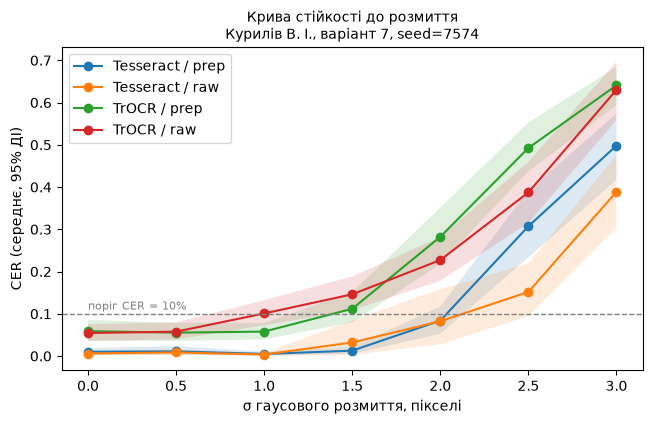

In [18]:
def boot_ci(x, n_boot=2000, alpha=0.05):
    x = np.asarray(x)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.quantile(means, [alpha / 2, 1 - alpha / 2])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (eng, prep), g in res.groupby(["engine", "prep"]):
    by_lvl = g.groupby("level")["cer"]
    mean = by_lvl.mean()
    ci = np.array([boot_ci(v) for _, v in by_lvl])
    ax.plot(mean.index, mean.values, marker="o", label=f"{eng} / {prep}")
    ax.fill_between(mean.index, ci[:, 0], ci[:, 1], alpha=0.15)
ax.axhline(0.10, ls="--", c="grey", lw=1)
ax.text(LEVELS[0], 0.11, "поріг CER = 10%", color="grey", fontsize=8)
ax.set_xlabel("σ гаусового розмиття, пікселі")
ax.set_ylabel("CER (середнє, 95% ДІ)")
ax.legend()
stamp(ax, "Крива стійкості до розмиття")
fig.savefig("figures/fig1_robustness.png", dpi=150, bbox_inches="tight")

### 11.2. Діаграма розмаху

Синтетика в зоні зламу (σ = 2) і рукописний IAM; трикутник позначає середнє

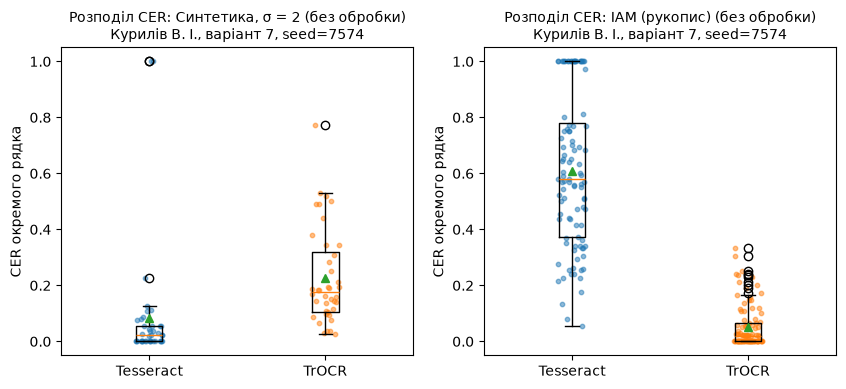

In [19]:
LVL = 2
panels = {f"Синтетика, σ = {LVL}": res[(res.level == LVL) & (res.prep == "raw")],
          "IAM (рукопис)": res_iam[res_iam.prep == "raw"]}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, sub) in zip(axes, panels.items()):
    groups = [g["cer"].values for _, g in sub.groupby("engine")]
    ax.boxplot(groups, tick_labels=sorted(sub.engine.unique()), showmeans=True)
    for k, g in enumerate(groups, start=1):
        ax.scatter(np.full(len(g), k) + rng.uniform(-0.08, 0.08, len(g)), g, s=10, alpha=0.5)
    ax.set_ylabel("CER окремого рядка")
    stamp(ax, f"Розподіл CER: {title} (без обробки)")
fig.savefig("figures/fig2_boxplot.png", dpi=150, bbox_inches="tight")

### 11.3. Впевненість і крива ризик-покриття

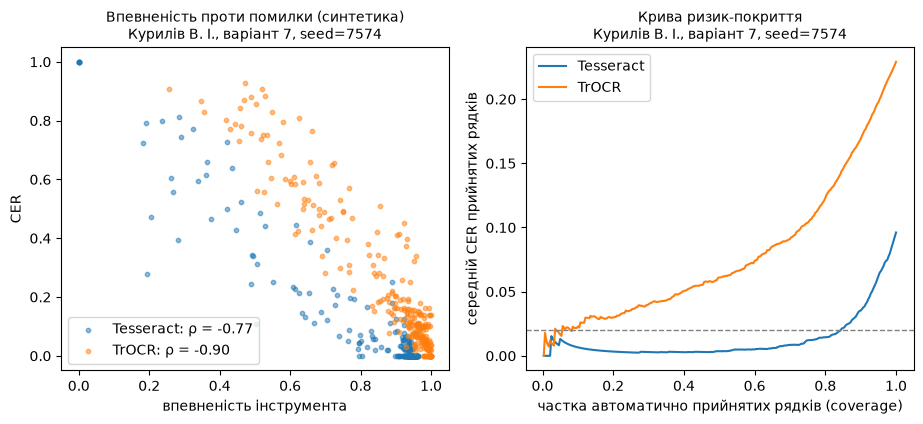

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for eng, g in res[res.prep == "raw"].groupby("engine"):
    rho, p = spearmanr(g.conf, g.cer)
    axes[0].scatter(g.conf, g.cer, s=10, alpha=0.5, label=f"{eng}: ρ = {rho:.2f}")
    g = g.sort_values("conf", ascending=False)
    coverage = np.arange(1, len(g) + 1) / len(g)
    risk = g.cer.cumsum().values / np.arange(1, len(g) + 1)
    axes[1].plot(coverage, risk, label=eng)
axes[0].set_xlabel("впевненість інструмента")
axes[0].set_ylabel("CER")
axes[0].legend()
stamp(axes[0], "Впевненість проти помилки (синтетика)")
axes[1].axhline(0.02, ls="--", c="grey", lw=1)
axes[1].set_xlabel("частка автоматично прийнятих рядків (coverage)")
axes[1].set_ylabel("середній CER прийнятих рядків")
axes[1].legend()
stamp(axes[1], "Крива ризик-покриття")
fig.savefig("figures/fig3_confidence.png", dpi=150, bbox_inches="tight")

### 11.4. Компроміс якість-швидкість

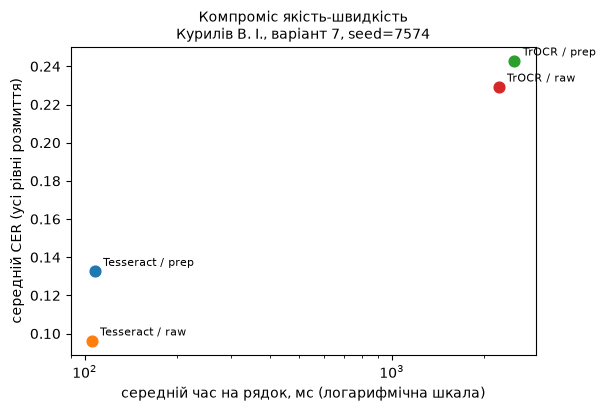

In [21]:
agg = (res.groupby(["engine", "prep"])
          .agg(cer=("cer", "mean"), ms=("sec", "mean")).reset_index())
agg["ms"] *= 1000
fig, ax = plt.subplots(figsize=(6, 4))
for r in agg.itertuples():
    ax.scatter(r.ms, r.cer, s=60)
    ax.annotate(f"{r.engine} / {r.prep}", (r.ms, r.cer), textcoords="offset points",
                xytext=(6, 4), fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("середній час на рядок, мс (логарифмічна шкала)")
ax.set_ylabel("середній CER (усі рівні розмиття)")
stamp(ax, "Компроміс якість-швидкість")
fig.savefig("figures/fig4_pareto.png", dpi=150, bbox_inches="tight")

### 11.5. Абляційний експеримент

σ = 1,5, обидва інструменти; кроки додаються послідовно, окремо перевіряється бінаризація Оцу без інших кроків

engine,Tesseract,TrOCR
step,,
без обробки,0.032,0.146
+ збільшення,0.036,0.141
+ різкість,0.004,0.129
+ бінаризація Оцу,0.013,0.112
лише Оцу,0.042,0.167


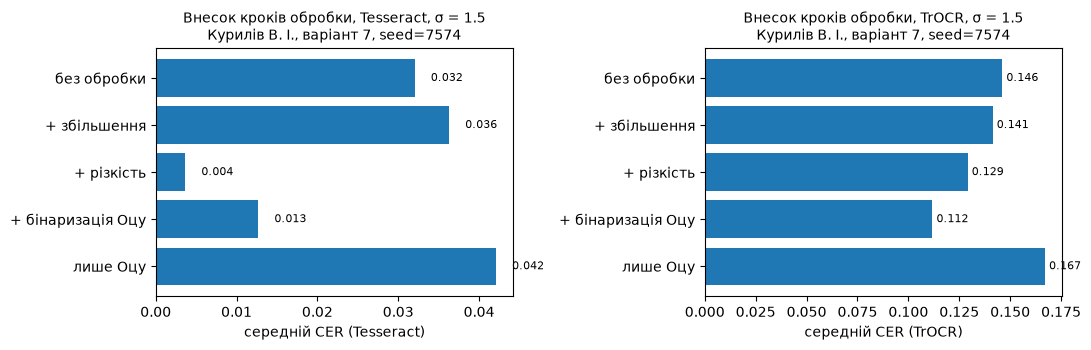

In [22]:
LVL = 1.5
ablation = {"без обробки": (), "+ збільшення": ("upscale",),
            "+ різкість": ("upscale", "sharpen"),
            "+ бінаризація Оцу": ("upscale", "sharpen", "binarize"),
            "лише Оцу": ("binarize",)}
abl = []
for r in ds[ds.level == LVL].itertuples():
    img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    for eng, fn in ENGINES.items():
        for name, steps in ablation.items():
            text, _, _ = fn(preprocess(img, steps))
            abl.append({"engine": eng, "step": name, "cer": cer(r.gt, text)})
abl = pd.DataFrame(abl).pivot_table(index="step", columns="engine", values="cer", sort=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, eng in zip(axes, abl.columns):
    ax.barh(abl.index[::-1], abl[eng].values[::-1])
    for y, v in enumerate(abl[eng].values[::-1]):
        ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=8)
    ax.set_xlabel(f"середній CER ({eng})")
    stamp(ax, f"Внесок кроків обробки, {eng}, σ = {LVL}")
fig.tight_layout()
fig.savefig("figures/fig5_ablation.png", dpi=150, bbox_inches="tight")
abl.round(3)

### 11.6. Діаграма замін символів

Рядки розпізнані хоча б частково (CER < 0,5); латинські літери позначено «(лат)»

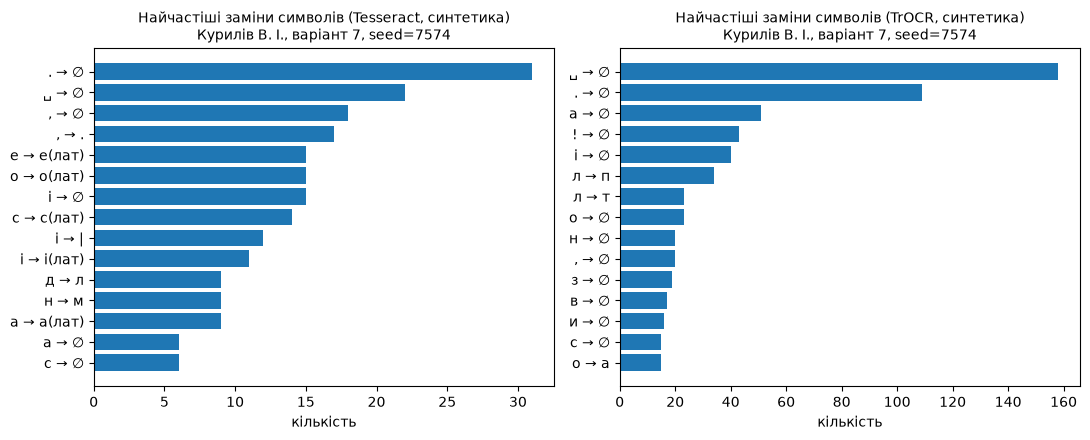

In [23]:
def sym(c):
    if c == " ":
        return "␣"
    if c.isascii() and c.isalpha():
        return f"{c}(лат)"
    return c

def confusions(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    pairs = []
    for op in Levenshtein.editops(gt, pred):
        if op.tag == "replace":
            pairs.append(f"{sym(gt[op.src_pos])} → {sym(pred[op.dest_pos])}")
        elif op.tag == "delete":
            pairs.append(f"{sym(gt[op.src_pos])} → ∅")
        else:
            pairs.append(f"∅ → {sym(pred[op.dest_pos])}")
    return pairs

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, eng in zip(axes, ["Tesseract", "TrOCR"]):
    cnt = Counter()
    part = res[(res.engine == eng) & (res.prep == "raw") & (res.cer < 0.5)]
    for r in part.itertuples():
        cnt.update(confusions(r.gt, r.pred))
    top = pd.Series(dict(cnt.most_common(15)))
    ax.barh(top.index[::-1], top.values[::-1])
    ax.set_xlabel("кількість")
    stamp(ax, f"Найчастіші заміни символів ({eng}, синтетика)")
fig.tight_layout()
fig.savefig("figures/fig6_confusions.png", dpi=150, bbox_inches="tight")

### 11.7. Порівняння CER на трьох групах даних

engine,Tesseract,TrOCR
group,,
"синтетика, σ = 0",0.006,0.054
IAM,0.608,0.050
"власні, укр.",0.877,0.069
"власні, англ.",0.182,0.071


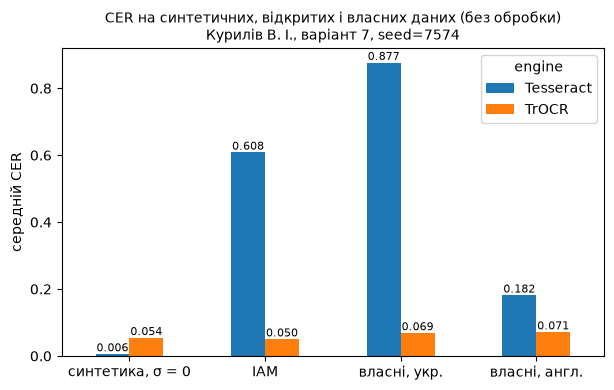

In [24]:
comp = pd.concat([
    res[(res.prep == "raw") & (res.level == 0)].assign(group="синтетика, σ = 0"),
    res_iam[res_iam.prep == "raw"].assign(group="IAM"),
    own[(own.prep == "raw") & (own.file != "english.jpg")].assign(group="власні, укр."),
    own[(own.prep == "raw") & (own.file == "english.jpg")].assign(group="власні, англ."),
])
tab = comp.pivot_table(index="group", columns="engine", values="cer", sort=False)
ax = tab.plot.bar(figsize=(7, 4), rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
ax.set_xlabel("")
ax.set_ylabel("середній CER")
stamp(ax, "CER на синтетичних, відкритих і власних даних (без обробки)")
ax.figure.savefig("figures/fig7_groups.png", dpi=150, bbox_inches="tight")
tab.round(3)

## 12. Обчислення для питань

### 1. Рівень, на якому CER вперше перевищує 10 %

In [25]:
curves = res.pivot_table(index=["engine", "prep"], columns="level", values="cer")
first = {cfg: next((lvl for lvl, v in row.items() if v > 0.10), None) for cfg, row in curves.iterrows()}
print(pd.Series(first, name="σ, де CER > 10 %"))
(curves * 100).round(1)

Tesseract  prep    2.5
           raw     2.5
TrOCR      prep    1.5
           raw     1.0
Name: σ, де CER > 10 %, dtype: float64


level           0.0  0.5   1.0   1.5   2.0   2.5   3.0
engine    prep                                        
Tesseract prep  1.0  1.1   0.5   1.3   8.4  30.7  49.8
          raw   0.6  0.8   0.4   3.2   8.2  15.2  38.9
TrOCR     prep  5.9  5.5   5.8  11.2  28.2  49.2  64.1
          raw   5.4  5.8  10.1  14.6  22.7  38.7  63.0

### 2. Ширина довірчих інтервалів і перевірка на збільшеній вибірці

In [26]:
ci_width = {}
for (eng, prep), g in res.groupby(["engine", "prep"]):
    for lvl, v in g.groupby("level")["cer"]:
        lo, hi = boot_ci(v)
        ci_width[(eng, prep, lvl)] = hi - lo
ci_width = pd.Series(ci_width).unstack()
print("Ширина 95% ДІ (частки CER):")
print(ci_width.round(3))
worst = ci_width.stack().idxmax()

Ширина 95% ДІ (частки CER):
                  0.0    0.5    1.0    1.5    2.0    2.5    3.0
Tesseract prep  0.015  0.021  0.009  0.017  0.063  0.154  0.162
          raw   0.012  0.014  0.007  0.083  0.128  0.129  0.176
TrOCR     prep  0.050  0.044  0.039  0.074  0.137  0.113  0.092
          raw   0.039  0.041  0.062  0.081  0.107  0.143  0.141


### 4. Медіана, середнє і повні провали

In [27]:
for title, sub in panels.items():
    for eng, g in sub.groupby("engine"):
        print(f"{title:22s} {eng:9s} медіана = {g.cer.median():.3f}  середнє = {g.cer.mean():.3f}  "
              f"частка CER >= 1: {(g.cer >= 1).mean():.2f}")
fails = pd.concat([sub[sub.cer >= 1].assign(group=t) for t, sub in panels.items()])
fails[["group", "engine", "gt", "pred", "cer"]]

Синтетика, σ = 2       Tesseract медіана = 0.021  середнє = 0.082  частка CER >= 1: 0.05
Синтетика, σ = 2       TrOCR     медіана = 0.176  середнє = 0.227  частка CER >= 1: 0.00
IAM (рукопис)          Tesseract медіана = 0.580  середнє = 0.608  частка CER >= 1: 0.22
IAM (рукопис)          TrOCR     медіана = 0.019  середнє = 0.050  частка CER >= 1: 0.00


,group,engine,gt,pred,cer
268,"Синтетика, σ = 2",Tesseract,"А молоде, дурне, попадеться ледачим людям, нав...",,1.0
828,"Синтетика, σ = 2",Tesseract,Старости сіли на ослоні біля столу.,,1.0
32,IAM (рукопис),Tesseract,is something deficient .,,1.0
52,IAM (рукопис),Tesseract,"James had grown up in Presbyterian Scotland ,",,1.0
64,IAM (рукопис),Tesseract,"if the cause of our pain is too deep seated ,",,1.0
68,IAM (рукопис),Tesseract,if the trouble is a complicated one,,1.0
80,IAM (рукопис),Tesseract,"It was a little complicated to work ,",,1.0
96,IAM (рукопис),Tesseract,"be by actual contact , or by sight reaction to...",,1.0
100,IAM (рукопис),Tesseract,aware of the moving footrope before,,1.0
152,IAM (рукопис),Tesseract,"and he knew how to do it , too : - When the",,1.0


### 5. Коефіцієнт Спірмена і поріг впевненості для CER <= 2 %

In [28]:
for eng, g in res[res.prep == "raw"].groupby("engine"):
    rho, p = spearmanr(g.conf, g.cer)
    g = g.sort_values("conf", ascending=False)
    risk = g.cer.cumsum().values / np.arange(1, len(g) + 1)
    ok = np.where(risk <= 0.02)[0]
    k = ok.max() if len(ok) else None
    if k is None:
        print(f"{eng}: ρ = {rho:.2f} (p = {p:.1e}); CER <= 2 % не досягається за жодного порогу")
    else:
        print(f"{eng}: ρ = {rho:.2f} (p = {p:.1e}); поріг впевненості = {g.conf.iloc[k]:.3f}")

Tesseract: ρ = -0.77 (p = 8.9e-57); поріг впевненості = 0.704
TrOCR: ρ = -0.90 (p = 8.3e-104); поріг впевненості = 0.996


### 8. Правила постобробки для найчастіших помилок Tesseract

In [29]:
LAT2CYR = str.maketrans("aceiopxyACEHIKMOPTXB", "асеіорхуАСЕНІКМОРТХВ")
DIG2CYR = str.maketrans("0631", "обзі")

def postprocess(text):
    text = str(text)
    cyr = len(re.findall(r"[а-яіїєґА-ЯІЇЄҐ]", text))
    lat = len(re.findall(r"[a-zA-Z]", text))
    if cyr > lat:
        words = []
        for w in text.split():
            if re.fullmatch(r"[^\w]*[aceiopxyACEHIKMOPTXB]+[^\w]*", w) or re.search(r"[а-яіїєґА-ЯІЇЄҐ]", w):
                w = w.translate(LAT2CYR)                 # 1: латинські гомогліфи -> кирилиця
            if re.fullmatch(r"[^\w]*[0631]+[^\w]*", w) or re.search(r"[а-яіїєґА-ЯІЇЄҐ]", w):
                w = w.translate(DIG2CYR)                 # 2: цифри-двійники літер -> літери
            words.append(w)
        text = " ".join(words)
    return re.sub(r"(?<=\s)\|(?=\s)", "і", text)       # 3: окрема риска | -> і

tess = res[(res.engine == "Tesseract") & (res.prep == "raw")].copy()
tess["pred_pp"] = tess.pred.map(postprocess)
tess["cer_pp"] = [cer(g, p) for g, p in zip(tess["gt"], tess["pred_pp"])]
(tess.groupby("level")[["cer", "cer_pp"]].mean() * 100).round(2)

,cer,cer_pp
level,,
0.0,0.59,0.20
0.5,0.84,0.36
1.0,0.35,0.21
1.5,3.20,3.04
2.0,8.23,7.39
2.5,15.17,14.05
3.0,38.86,37.91


### 9. CER на власних фото проти синтетичних і відкритих даних

In [30]:
ref = {"синтетика": res[(res.prep == "raw") & (res.level == 0)].groupby("engine").cer.mean(),
       "IAM": res_iam[res_iam.prep == "raw"].groupby("engine").cer.mean()}
own_raw = own[own.prep == "raw"].pivot_table(index="file", columns="engine", values="cer")
print("CER власних фото (без обробки):")
print(own_raw.round(3))
for name, r in ref.items():
    print(f"\nУ скільки разів CER власних фото вищий, ніж {name}:")
    print((own_raw / r).round(1))

CER власних фото (без обробки):
engine           Tesseract  TrOCR
file                             
english.jpg          0.182  0.071
page_angle.jpg       0.867  0.102
page_flat.jpg        0.811  0.042
page_shadow.jpg      0.952  0.062

У скільки разів CER власних фото вищий, ніж синтетика:
engine           Tesseract  TrOCR
file                             
english.jpg           30.6    1.3
page_angle.jpg       146.1    1.9
page_flat.jpg        136.6    0.8
page_shadow.jpg      160.4    1.1

У скільки разів CER власних фото вищий, ніж IAM:
engine           Tesseract  TrOCR
file                             
english.jpg            0.3    1.4
page_angle.jpg         1.4    2.0
page_flat.jpg          1.3    0.8
page_shadow.jpg        1.6    1.2


### 10. Особливість варіанта: друкований інструмент проти рукописного

In [31]:
feature = pd.DataFrame({
    "друк (синтетика, σ = 0)": ref["синтетика"],
    "рукопис IAM": ref["IAM"],
    "власний рукопис, укр.": own[(own.prep == "raw") & (own.file != "english.jpg")].groupby("engine").cer.mean(),
    "власний рукопис, англ.": own[(own.prep == "raw") & (own.file == "english.jpg")].groupby("engine").cer.mean(),
}).T
feature["Tesseract / TrOCR"] = (feature.Tesseract / feature.TrOCR).round(1)
feature.round(3)

engine,Tesseract,TrOCR,Tesseract / TrOCR
"друк (синтетика, σ = 0)",0.006,0.054,0.1
рукопис IAM,0.608,0.050,12.1
"власний рукопис, укр.",0.877,0.069,12.8
"власний рукопис, англ.",0.182,0.071,2.5


## 13. П'ять найгірших зразків кожного інструмента

In [32]:
def category(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    ratio = len(pred) / max(1, len(gt))
    if not pred:
        return "детекція: текст не знайдено"
    if Levenshtein.distance(gt, pred) / max(1, len(gt)) >= 0.8:
        return "галюцинація: вигадані слова"
    if ratio < 0.7:
        return "пропуск частини рядка"
    if ratio > 1.3:
        return "вставлення зайвого тексту"
    return "заміна символів"

pool = pd.concat([
    res[res.prep == "raw"].merge(ds[["id", "level", "path"]], on=["id", "level"]).assign(data="синтетика"),
    res_iam[res_iam.prep == "raw"].merge(iam[["idx", "path"]], on="idx").assign(data="IAM"),
])
worst5 = pool.sort_values("cer", ascending=False).groupby("engine").head(5).sort_values(["engine", "cer"], ascending=[True, False])
worst5["category"] = [category(g, p) for g, p in zip(worst5["gt"], worst5["pred"])]
worst5[["engine", "data", "level", "gt", "pred", "cer", "category"]]

,engine,data,level,gt,pred,cer,category
40,Tesseract,IAM,NaN,"It was a little complicated to work ,",,1.000000,детекція: текст не знайдено
152,Tesseract,IAM,NaN,""" Willie , "" the judge said huskily ,",,1.000000,детекція: текст не знайдено
164,Tesseract,IAM,NaN,"of the work is done . "" He held out a card .",,1.000000,детекція: текст не знайдено
516,Tesseract,синтетика,3.0,Ні за що у світі не скажу...,,1.000000,детекція: текст не знайдено
190,Tesseract,IAM,NaN,"them out . "" He 's the carrotty lad , isn't he...",,1.000000,детекція: текст не знайдено
517,TrOCR,синтетика,3.0,Ні за що у світі не скажу...,НИФУ ЕТНЕДД,0.928571,галюцинація: вигадані слова
307,TrOCR,синтетика,3.0,— Зачим же він узяв у нас одну нашу радість?,конкраторы,0.909091,галюцинація: вигадані слова
305,TrOCR,синтетика,2.5,— Зачим же він узяв у нас одну нашу радість?,-100787827 207 107117 5017,0.909091,галюцинація: вигадані слова
209,TrOCR,синтетика,3.0,Та й що то за дитина була!,темпинных,0.884615,галюцинація: вигадані слова
251,TrOCR,синтетика,3.0,А що тоді буде з Марусею?,Авга должный,0.880000,галюцинація: вигадані слова


## 14. Збереження результатів у JSON

In [33]:
import transformers

def file_sha256(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

VERSIONS = {"Tesseract": f"Tesseract {pytesseract.get_tesseract_version()}",
            "TrOCR": f"transformers {transformers.__version__}"}
records = []
for r in own.itertuples():
    lang = "en" if r.file == "english.jpg" else "uk"
    params = ({"lang": "eng" if lang == "en" else "ukr+eng", "psm": 6, "oem": 1}
              if r.engine == "Tesseract" else
              {"model": "microsoft/trocr-base-handwritten" if lang == "en" else "Hukyl/trocr-large-uk-handwritten",
               "num_beams": 1, "segmentation": "split_lines"})
    records.append({"file": r.file, "image_sha256": file_sha256(f"my_photos/{r.file}"),
                    "taken": r.taken, "camera": r.camera,
                    "engine": r.engine, "version": VERSIONS[r.engine], "params": params,
                    "preprocessing": r.prep, "confidence": round(r.conf, 4), "seconds": round(r.sec, 3),
                    "cer": round(r.cer, 4), "wer": round(r.wer, 4), "text": r.pred})
with open("own_results.json", "w", encoding="utf-8") as f:
    json.dump(records, f, ensure_ascii=False, indent=2)
print(json.dumps(records[4], ensure_ascii=False, indent=2))

{
  "file": "page_angle.jpg",
  "image_sha256": "b5bba6d654c19a023ec7fd011b389383987b6e7ae394aa4c6800c7059e7b253f",
  "taken": "2026:10:17 19:22:29",
  "camera": "iPhone 15",
  "engine": "Tesseract",
  "version": "Tesseract 5.5.3",
  "params": {
    "lang": "ukr+eng",
    "psm": 6,
    "oem": 1
  },
  "preprocessing": "raw",
  "confidence": 0.3224,
  "seconds": 0.54,
  "cer": 0.8672,
  "wer": 1.0,
  "text": "EE п  ' и жр'- лі ae кана ой б бач нафленс ар, rocugunre, poodpa, ОТ Hy ypu Pf. FTC3-4F 1? coGmpux 208 6 р-"
}


## 15. Перевірка гіпотез

| Гіпотеза | Прогноз | Результат | Оцінка |
|---|---|---|---|
| **H1** | Tesseract при σ = 0: CER <= 2 %; CER > 10 % при σ ~ 2 | CER при σ = 0 становить 0,6 %; поріг 10 % перевищено при σ = 2,5 (при σ = 2 CER 8,2 %) | перша частина підтверджена, друга спростована |
| **H2** | IAM: TrOCR ≤ 10 %, Tesseract ≥ 40 % | TrOCR 5,0 %, Tesseract 60,8 % | підтверджено |
| **H3** | Оцу погіршить TrOCR щонайменше на 2 п.п. | сама Оцу: 14,6 % → 16,7 % (+2,1 п.п.); Оцу після збільшення і різкості: 12,9 % → 11,2 % | підтверджено частково |
| **H4** | CER на власних фото у 3-5 разів вищий, ніж на IAM | TrOCR: 4,2–10,2 % проти 5,0 % (0,8–2 рази); Tesseract: 81–95 % проти 60,8 % (1,3–1,6 раза); найгірша умова для TrOCR - кут (10,2 %), для Tesseract - тінь (95,2 %) | спростовано |

## 16. Висновки

1. **Друкований текст:** кращий Tesseract. CER 0,6 % проти 5,4 % у TrOCR, і він у ~20 разів швидший.
2. **Рукописний текст (особливість варіанта):** кращий TrOCR. На IAM CER 5,0 % проти 60,8 %, на власному рукописі 4–10 % проти 81–95 %.
3. **Розмиття:** Tesseract перевищує CER 10 % при σ = 2,5, а TrOCR вже при σ = 1.
4. **Обробка:** найбільше допомагає різкість (Tesseract при σ = 1,5: 3,2 % → 0,4 %), а Оцу без підготовки шкодить.
5. **Впевненість:** за порогом 0,70 можна автоматично прийняти 84 % рядків Tesseract із CER ≤ 2 %.
6. **Помилки:** Tesseract плутає кириличні літери з латинськими (правила зменшили CER з 0,59 % до 0,20 %). TrOCR обрізає кінці рядків і вигадує текст на розмитих зображеннях.
7. **Рекомендація:** для друку використовувати Tesseract, для рукопису TrOCR.